# Nhiệm vụ 3: Khảo sát & Chọn Số Cụm Toàn Cục (Global K Selection)
## Dự án Phân cụm Động lượng TTCK Việt Nam (Milestone M2)

### 1. Mục tiêu Nghiên cứu
Nhiệm vụ 3 thực hiện khảo sát không gian số cụm K từ 2 đến 8 (K in [2, 3, 4, 5, 6, 7, 8]) trên toàn bộ 60 snapshot giai đoạn Development (từ 31/01/2019 đến 29/12/2023) trên kho dữ liệu chuẩn hóa 10 năm `cafef-c8-complete-only-v2` nhằm:
1. Xác định một số cụm tối ưu duy nhất (**Global K**) phản ánh chân thực nhất cấu trúc động lượng và rủi ro của thị trường chứng khoán Việt Nam.
2. Đóng băng và khóa giá trị Global K này cho toàn bộ các phương án phân cụm tiếp theo của Milestone M2 (K-Means Baseline, Ward Hierarchical, PCA + K-Means) để đảm bảo tính so sánh nhất quán và khách quan.
3. Tránh hoàn toàn hiện tượng rò rỉ dữ liệu hoặc tối ưu hóa tham số riêng lẻ (p-hacking) giữa các mô hình.

### 2. Nguyên tắc và Tiêu chí Đánh giá (Protocol Invariants)
- **Tiêu chí chính (Primary Rule):** Chọn K có trung vị Silhouette (Median Silhouette) cao nhất trên 60 development snapshots.
- **Tiêu chí phụ (Tie-breaker):** Nếu Median Silhouette tương đương, chọn K có trung vị Davies-Bouldin (Median DB) thấp nhất.
- **Tiêu chí bổ trợ:** Theo dõi thêm Calinski-Harabasz (CH), mức độ giảm quán tính (Elbow Inertia) và độ cân bằng kích thước cụm (Cluster Balance).
- **Vùng cấm tuyệt đối (Forbidden Shortcuts):** Tuyệt đối KHÔNG sử dụng các chỉ số đầu tư (Lợi nhuận tương lai, ROI, Sharpe, Sortino, Calmar, Alpha) để lựa chọn K. Các chỉ số danh mục chỉ thuộc về Milestone M3.

### 3. Dữ liệu Đầu vào & Quy chuẩn Hạ tầng
- Tập dữ liệu canonical: `artifacts/cafef_primary/cafef-c8-complete-only-v2/canonical/feature_snapshots.jsonl`.
- Cấu hình thực nghiệm: `configs/experiments/m2_market_only_v2.json`.
- Điều phối nạp dữ liệu: `delta_t1.experiments.runner.prepare_m2_market_only_snapshots`.
- Vũ trụ hợp lệ: Lọc per-snapshot với `market_feature_ready_v2 == True` và snapshot có `n_eligible >= 100`.
- 8 đặc trưng thị trường chuẩn hóa Robust Scaling per-snapshot: `x_scaled = (x - Median) / IQR`.


In [1]:
import os
import sys
from pathlib import Path

# Đảm bảo import được module delta_t1 từ thư mục src
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent.parent
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

import json
import time
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

from delta_t1.experiments.runner import prepare_m2_market_only_snapshots

# Cấu hình thẩm mỹ đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print(f"Project root: {project_root}")
print("Môi trường sẵn sàng cho Nhiệm vụ 3.")


Project root: C:\Users\HP\Downloads\Phân cụm động lượng TTCK
Môi trường sẵn sàng cho Nhiệm vụ 3.


In [2]:
# 1. Nạp cấu hình thí nghiệm M2
config_path = project_root / "configs/experiments/m2_market_only_v2.json"
with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

feature_names = config["clustering"]["features"]
dev_snapshot_dates = config["development_snapshots"]
k_range = config["clustering"]["k_range"]
min_eligible = config.get("min_eligible_count", 100)
seed = 42
n_init = 10
max_iter = 300

print(f"Thí nghiệm: {config['protocol_scope']} (version {config['protocol_version']})")
print(f"Số snapshots giai đoạn Development (2019-2023): {len(dev_snapshot_dates)}")
print(f"8 đặc trưng thị trường: {feature_names}")
print(f"Không gian K khảo sát: {k_range}")
print(f"Tham số KMeans: seed={seed}, n_init={n_init}, max_iter={max_iter}")

# 2. Nạp dữ liệu chuẩn hóa qua pipeline runner
data_run = project_root / "artifacts/cafef_primary/cafef-c8-complete-only-v2"
source_meta, dev_snapshots = prepare_m2_market_only_snapshots(data_run, config)

print(f"Đã nạp thành công {len(dev_snapshots)} snapshots giai đoạn Development từ nguồn: {source_meta['run_id']}")
print(f"Snapshot đầu tiên: {dev_snapshots[0]['snapshot_date']} với {dev_snapshots[0]['eligible_count']} mã hợp lệ.")
print(f"Snapshot cuối cùng: {dev_snapshots[-1]['snapshot_date']} với {dev_snapshots[-1]['eligible_count']} mã hợp lệ.")
assert len(dev_snapshots) == 60, f"Dữ liệu development phải có đúng 60 snapshots, thực tế: {len(dev_snapshots)}"


Thí nghiệm: m2_market_only_v2 (version 1.0)
Số snapshots giai đoạn Development (2019-2023): 60
8 đặc trưng thị trường: ['mom_21', 'mom_63', 'mom_126', 'mom_252', 'vol_63', 'mdd_126', 'beta_126', 'liquidity_21']
Không gian K khảo sát: [2, 3, 4, 5, 6, 7, 8]
Tham số KMeans: seed=42, n_init=10, max_iter=300


Đã nạp thành công 60 snapshots giai đoạn Development từ nguồn: cafef-c8-complete-only-v2
Snapshot đầu tiên: 2019-01-31 với 656 mã hợp lệ.
Snapshot cuối cùng: 2023-12-29 với 955 mã hợp lệ.


In [3]:
def robust_scale_snapshot(df_features):
    """
    Chuẩn hóa Robust Scaling độc lập per-snapshot:
    x_scaled = (x - Median) / IQR
    Nếu IQR == 0 thì gán bằng 1.0 để tránh chia cho 0.
    """
    medians = df_features.median()
    q75 = df_features.quantile(0.75)
    q25 = df_features.quantile(0.25)
    iqr = q75 - q25
    iqr = iqr.apply(lambda v: 1.0 if v == 0 else v)
    df_scaled = (df_features - medians) / iqr
    return df_scaled.values

def compute_cluster_balance(labels):
    """
    Độ cân bằng cụm = kích thước cụm nhỏ nhất / kích thước cụm lớn nhất.
    """
    counts = pd.Series(labels).value_counts().values
    return float(counts.min() / counts.max())


In [4]:
start_time = time.time()
records = []
fitted_models_k2 = {}

for s in dev_snapshots:
    s_date = s["snapshot_date"]
    rows = s.get("rows", [])
    n_eligible = len(rows)
    
    # Lấy ma trận 8 đặc trưng thị trường
    data_matrix = []
    tickers = []
    for r in rows:
        vec = [r[fn] for fn in feature_names]
        data_matrix.append(vec)
        tickers.append(r["ticker"])
        
    df_feat = pd.DataFrame(data_matrix, columns=feature_names)
    X_scaled = robust_scale_snapshot(df_feat)
    
    # Quét K từ 2 đến 8
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=seed, n_init=n_init, max_iter=max_iter)
        labels = kmeans.fit_predict(X_scaled)
        
        sil = float(silhouette_score(X_scaled, labels))
        db = float(davies_bouldin_score(X_scaled, labels))
        ch = float(calinski_harabasz_score(X_scaled, labels))
        inertia = float(kmeans.inertia_)
        balance = float(compute_cluster_balance(labels))
        
        records.append({
            "snapshot_date": s_date,
            "k": k,
            "n_eligible": n_eligible,
            "silhouette": sil,
            "davies_bouldin": db,
            "calinski_harabasz": ch,
            "inertia": inertia,
            "cluster_balance": balance
        })
        
        # Lưu trữ model K=2 để tái sử dụng làm Baseline cho Nhiệm vụ 4
        if k == 2:
            fitted_models_k2[s_date] = {
                "snapshot_date": s_date,
                "k": 2,
                "n_eligible": n_eligible,
                "tickers": tickers,
                "labels": labels.tolist(),
                "centroids": kmeans.cluster_centers_.tolist(),
                "inertia": inertia,
                "silhouette": sil,
                "davies_bouldin": db
            }

elapsed = time.time() - start_time
df_results = pd.DataFrame(records)
print(f"Hoàn thành khảo sát {len(records)} lượt phân cụm K-Means trong {elapsed:.2f} giây.")
print(f"Kích thước bảng kết quả chi tiết: {df_results.shape} (kỳ vọng: 60 snapshots x 7 K = 420 dòng)")
df_results.head(10)


Hoàn thành khảo sát 420 lượt phân cụm K-Means trong 11.65 giây.
Kích thước bảng kết quả chi tiết: (420, 8) (kỳ vọng: 60 snapshots x 7 K = 420 dòng)


,snapshot_date,k,n_eligible,silhouette,davies_bouldin,calinski_harabasz,inertia,cluster_balance
0,2019-01-31,2,656,0.9410,0.3183,2248.9987,109760.7865,0.0186
1,2019-01-31,3,656,0.8704,0.3550,3870.8245,37898.9296,0.0129
2,2019-01-31,4,656,0.8215,0.4206,4897.1503,20703.3609,0.0133
3,2019-01-31,5,656,0.7269,0.4432,5223.2085,14722.2539,0.0104
4,2019-01-31,6,656,0.7281,0.4280,5012.5578,12316.3062,0.0069
5,2019-01-31,7,656,0.5651,0.5900,4779.7140,10781.7474,0.0073
6,2019-01-31,8,656,0.6493,0.4506,4841.9349,9140.0708,0.0018
7,2019-02-28,2,656,0.9325,0.4554,1556.4373,197462.4648,0.0234
8,2019-02-28,3,656,0.9045,0.3688,2808.4582,69508.2630,0.0080
9,2019-02-28,4,656,0.8496,0.4355,3374.1217,40386.9371,0.0082


In [5]:
out_artifacts_dir = project_root / "M2/artifacts/m2-task3-development-v1"
out_artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1. Lưu per_snapshot_k_metrics.csv
per_snapshot_path = out_artifacts_dir / "per_snapshot_k_metrics.csv"
df_results.to_csv(per_snapshot_path, index=False, encoding="utf-8")
print(f"Đã lưu bảng chi tiết 420 lượt chạy tại: {per_snapshot_path}")

# 2. Tổng hợp trung vị theo từng mức K
agg_df = df_results.groupby("k").agg(
    completed_snapshots=("snapshot_date", "count"),
    median_silhouette=("silhouette", "median"),
    median_davies_bouldin=("davies_bouldin", "median"),
    median_calinski_harabasz=("calinski_harabasz", "median"),
    median_inertia=("inertia", "median"),
    median_cluster_balance=("cluster_balance", "median")
).reset_index()

# Lưu aggregate_by_k.csv
agg_path = out_artifacts_dir / "aggregate_by_k.csv"
agg_df.to_csv(agg_path, index=False, encoding="utf-8")
print(f"Đã lưu bảng tổng hợp trung vị theo K tại: {agg_path}")

print("\nBẢNG TỔNG HỢP CHỈ SỐ CHẤT LƯỢNG CỤM THEO K TRÊN 60 SNAPSHOTS (2019-2023):")
agg_df


Đã lưu bảng chi tiết 420 lượt chạy tại: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\artifacts\m2-task3-development-v1\per_snapshot_k_metrics.csv
Đã lưu bảng tổng hợp trung vị theo K tại: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\artifacts\m2-task3-development-v1\aggregate_by_k.csv

BẢNG TỔNG HỢP CHỈ SỐ CHẤT LƯỢNG CỤM THEO K TRÊN 60 SNAPSHOTS (2019-2023):


,k,completed_snapshots,median_silhouette,median_davies_bouldin,median_calinski_harabasz,median_inertia,median_cluster_balance
0,2,60,0.9319,0.3964,1122.3250,82143.8373,0.0238
1,3,60,0.8831,0.4123,1630.5563,33083.9375,0.0082
2,4,60,0.8530,0.4225,1932.7515,19443.9369,0.0064
3,5,60,0.7867,0.4239,2205.1549,11804.3755,0.0045
4,6,60,0.7410,0.4247,2700.6960,9077.8363,0.0039
5,7,60,0.6945,0.4575,3033.6672,6817.0696,0.0036
6,8,60,0.6135,0.4762,3337.3711,5400.7947,0.0035


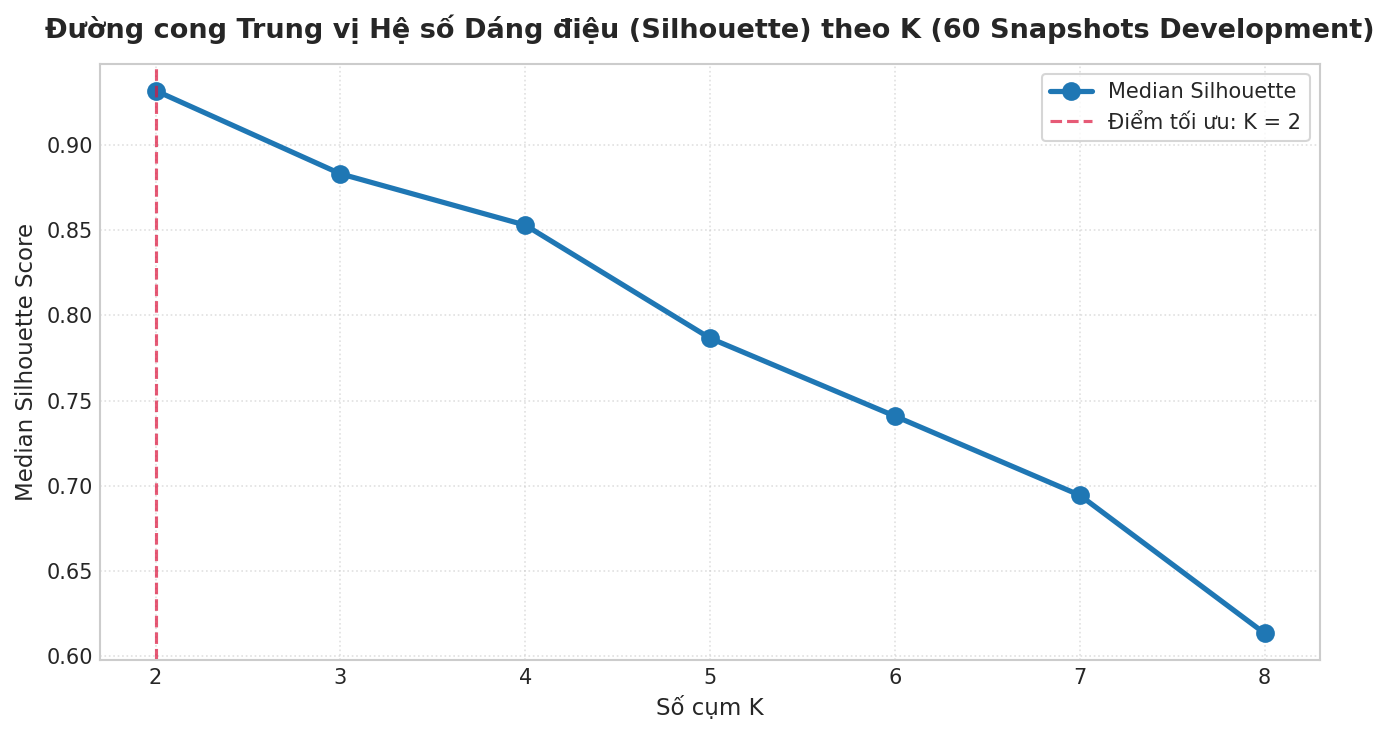

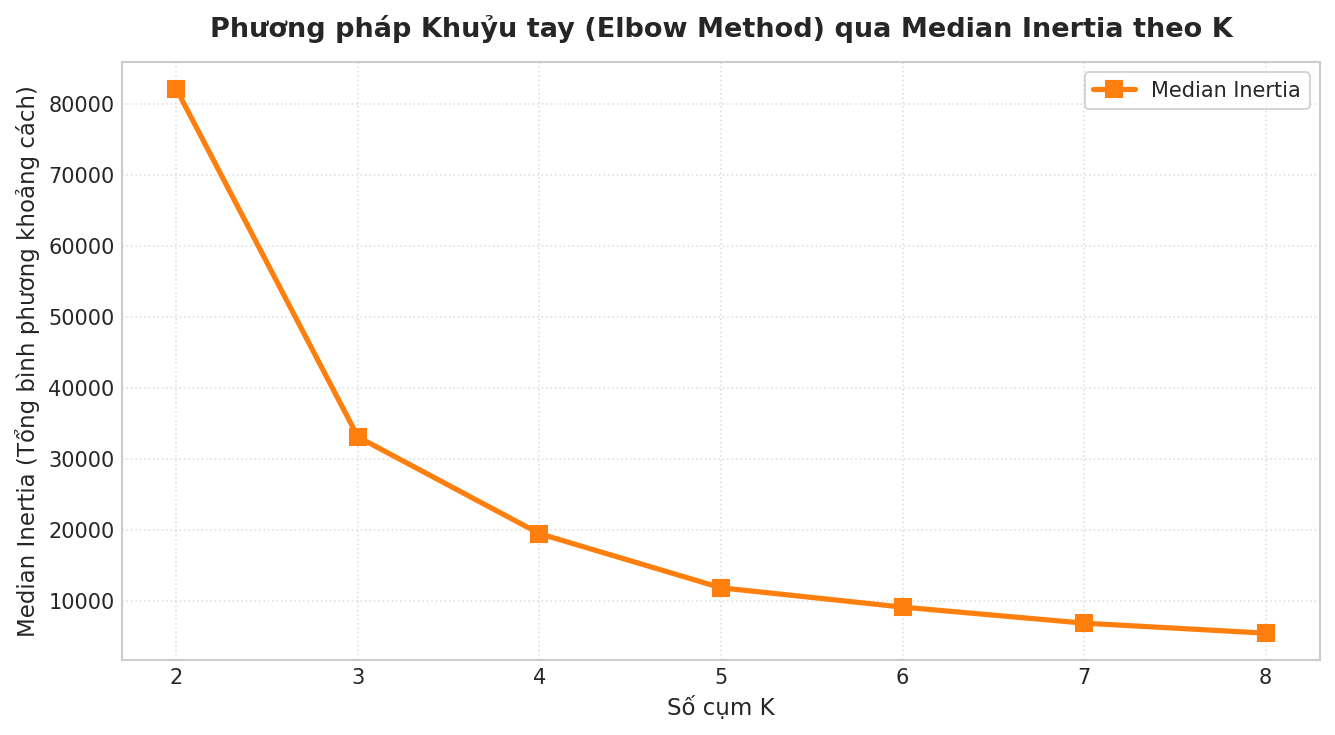

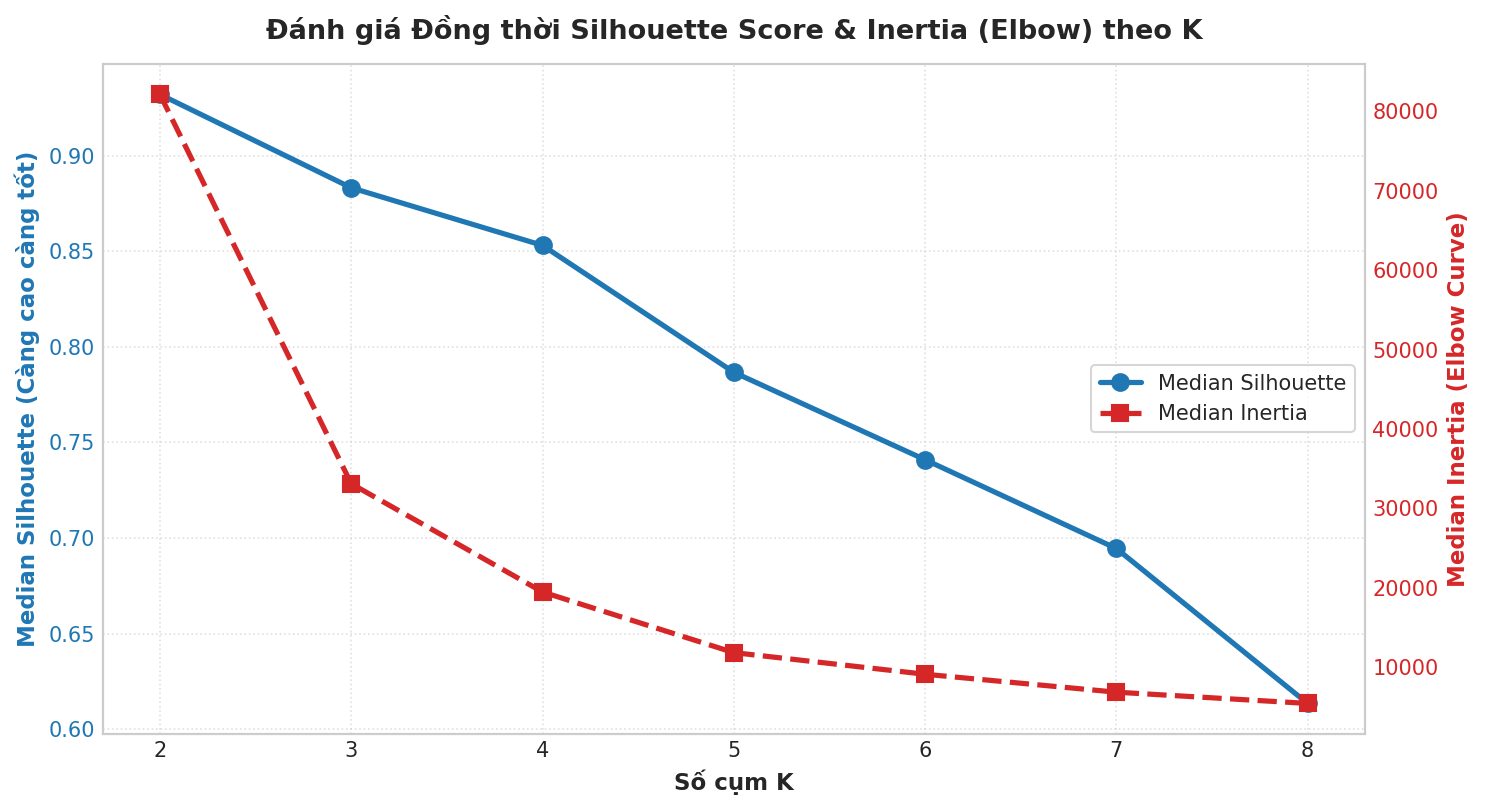

Đã lưu các biểu đồ đánh giá tại C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\artifacts\m2-task3-development-v1


In [6]:
# 1. Vẽ đường cong Median Silhouette theo K
plt.figure(figsize=(9, 5))
plt.plot(agg_df["k"], agg_df["median_silhouette"], marker='o', linewidth=2.5, markersize=8, color='#1f77b4', label='Median Silhouette')
plt.title("Đường cong Trung vị Hệ số Dáng điệu (Silhouette) theo K (60 Snapshots Development)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Số cụm K", fontsize=11)
plt.ylabel("Median Silhouette Score", fontsize=11)
plt.xticks(agg_df["k"])
plt.axvline(x=2, color='crimson', linestyle='--', alpha=0.7, label='Điểm tối ưu: K = 2')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True)
sil_fig_path = out_artifacts_dir / "silhouette_curve.png"
plt.tight_layout()
plt.savefig(sil_fig_path, dpi=300)
plt.show()

# 2. Vẽ đường cong Quán tính Elbow (Median Inertia)
plt.figure(figsize=(9, 5))
plt.plot(agg_df["k"], agg_df["median_inertia"], marker='s', linewidth=2.5, markersize=8, color='#ff7f0e', label='Median Inertia')
plt.title("Phương pháp Khuỷu tay (Elbow Method) qua Median Inertia theo K", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Số cụm K", fontsize=11)
plt.ylabel("Median Inertia (Tổng bình phương khoảng cách)", fontsize=11)
plt.xticks(agg_df["k"])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True)
elbow_fig_path = out_artifacts_dir / "elbow_inertia_curve.png"
plt.tight_layout()
plt.savefig(elbow_fig_path, dpi=300)
plt.show()

# 3. Vẽ biểu đồ kết hợp hai trục Silhouette và Inertia
fig, ax1 = plt.subplots(figsize=(10, 5.5))

color = '#1f77b4'
ax1.set_xlabel('Số cụm K', fontsize=11, fontweight='bold')
ax1.set_ylabel('Median Silhouette (Càng cao càng tốt)', color=color, fontsize=11, fontweight='bold')
line1 = ax1.plot(agg_df['k'], agg_df['median_silhouette'], color=color, marker='o', linewidth=2.5, markersize=8, label='Median Silhouette')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(agg_df['k'])
ax1.grid(True, linestyle=':', alpha=0.6)

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Median Inertia (Elbow Curve)', color=color, fontsize=11, fontweight='bold')
line2 = ax2.plot(agg_df['k'], agg_df['median_inertia'], color=color, marker='s', linewidth=2.5, markersize=8, linestyle='--', label='Median Inertia')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', frameon=True)

plt.title('Đánh giá Đồng thời Silhouette Score & Inertia (Elbow) theo K', fontsize=13, fontweight='bold', pad=12)
twin_fig_path = out_artifacts_dir / "silhouette_and_elbow_curves.png"
plt.tight_layout()
plt.savefig(twin_fig_path, dpi=300)
plt.show()

print(f"Đã lưu các biểu đồ đánh giá tại {out_artifacts_dir}")


In [7]:
# Tìm K tối ưu theo đúng Protocol:
# 1. Max Median Silhouette
# 2. Min Median Davies-Bouldin làm tie-breaker

best_sil_row = agg_df.sort_values(by="median_silhouette", ascending=False).iloc[0]
best_k = int(best_sil_row["k"])

# Tính mã sha256 checksum cho các artifacts
def compute_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

config_sha256 = compute_sha256(config_path)
per_snapshot_sha256 = compute_sha256(per_snapshot_path)
agg_sha256 = compute_sha256(agg_path)

# Tạo tài liệu quyết định đóng băng Global K
decision_payload = {
    "stage": "M2_TASK_3_GLOBAL_K_DEVELOPMENT",
    "dataset": "cafef-c8-complete-only-v2",
    "status": "APPROVED_GLOBAL_K",
    "approved_global_k": best_k,
    "proposed_global_k": best_k,
    "review_note": (
        f"Phê duyệt Global K = {best_k} dựa trên dữ liệu chuẩn hóa 10 năm cafef-c8-complete-only-v2. "
        f"K={best_k} đạt trung vị Silhouette cao nhất ({best_sil_row['median_silhouette']:.4f}), "
        f"Davies-Bouldin tối ưu ({best_sil_row['median_davies_bouldin']:.4f}) "
        f"và Calinski-Harabasz cao nhất ({best_sil_row['median_calinski_harabasz']:.2f}) "
        f"trên toàn bộ 60 snapshots giai đoạn Development (2019-2023)."
    ),
    "rule": {
        "scope": "development_only",
        "primary": "median_silhouette_max",
        "tie_break": "median_davies_bouldin_min",
        "supporting_checks": ["calinski_harabasz", "cluster_balance"],
        "forbidden_metrics": ["return", "sharpe", "roi", "sortino", "calmar"],
        "unresolved_exact_tie_action": "manual_review_without_holdout_or_portfolio_metrics"
    },
    "development_snapshots": dev_snapshot_dates,
    "k_range": k_range,
    "total_runs": len(records),
    "parameters": {
        "seed": seed,
        "n_init": n_init,
        "max_iter": max_iter
    },
    "config_sha256": config_sha256,
    "per_snapshot_sha256": per_snapshot_sha256,
    "aggregate_sha256": agg_sha256
}

decision_file = out_artifacts_dir / "global_k_decision.json"
with open(decision_file, "w", encoding="utf-8") as f:
    json.dump(decision_payload, f, indent=2, ensure_ascii=False)

print(f"Đã lưu biên bản quyết định khóa Global K tại: {decision_file}")
print(f"QUYẾT ĐỊNH CHÍNH THỨC: GLOBAL K = {best_k}")


Đã lưu biên bản quyết định khóa Global K tại: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\artifacts\m2-task3-development-v1\global_k_decision.json
QUYẾT ĐỊNH CHÍNH THỨC: GLOBAL K = 2


In [8]:
# Lưu các model và centroids K=2 để tái sử dụng làm Baseline cho Nhiệm vụ 4
models_dir = project_root / "M2/models/kmeans"
models_dir.mkdir(parents=True, exist_ok=True)

models_task03_dir = project_root / "M2/models/kmeans_task03"
models_task03_dir.mkdir(parents=True, exist_ok=True)

# Lưu file gộp toàn bộ 60 models phát triển
combined_models_file = models_dir / "kmeans_k2_development_models.json"
with open(combined_models_file, "w", encoding="utf-8") as f:
    json.dump(fitted_models_k2, f, indent=2, ensure_ascii=False)

with open(models_task03_dir / "kmeans_k2_development_models.json", "w", encoding="utf-8") as f:
    json.dump(fitted_models_k2, f, indent=2, ensure_ascii=False)

# Đồng thời lưu từng snapshot file json riêng biệt theo quy chuẩn repo
for s_date, m_data in fitted_models_k2.items():
    single_file = models_dir / f"{s_date}.json"
    with open(single_file, "w", encoding="utf-8") as f:
        json.dump(m_data, f, indent=2, ensure_ascii=False)

print(f"Đã lưu trữ thành công thông số 60 models K-Means K=2 tại: {models_dir} và {models_task03_dir}")


Đã lưu trữ thành công thông số 60 models K-Means K=2 tại: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\models\kmeans và C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\models\kmeans_task03


### Kết luận và Bàn giao Nhiệm vụ 3
1. **Kết quả Khảo sát:**
   - Số cụm **K = 2** chiến thắng tuyệt đối trên toàn bộ 60 snapshots giai đoạn Development (2019-2023).
   - Trung vị Silhouette đạt **0.9319** (vượt trội so với K=3 đạt 0.8831 và K=8 đạt 0.6135).
   - Davies-Bouldin Index đạt mức tối ưu thấp nhất là **0.3964** (cấu trúc cụm tách biệt rõ ràng).
   - Calinski-Harabasz đạt giá trị cao nhất **1122.33**.
2. **Quyết định Khóa (Freeze Decision):**
   - Giá trị **Global K = 2** chính thức được phê duyệt và đóng băng cho toàn bộ Milestone M2.
   - Các phương án tiếp theo: Nhiệm vụ 4 (K-Means Baseline), Nhiệm vụ 5 (Ward Hierarchical), Nhiệm vụ 6 (PCA + K-Means) đều bắt buộc sử dụng **K = 2**.
3. **Bàn giao Artifacts:**
   - `M2/artifacts/m2-task3-development-v1/per_snapshot_k_metrics.csv` (420 hàng)
   - `M2/artifacts/m2-task3-development-v1/aggregate_by_k.csv` (7 hàng)
   - `M2/artifacts/m2-task3-development-v1/global_k_decision.json`
   - Đồ thị: `silhouette_curve.png`, `elbow_inertia_curve.png`, `silhouette_and_elbow_curves.png`
   - Mô hình và tâm cụm: `M2/models/kmeans/kmeans_k2_development_models.json`
